## **Ejercicio**

Realiza un sistema de control difuso para el control de inventario basado en la demanda del mercado y el inventario actual. El sistema intentará ajustar el nivel de inventario para minimizar el costo de mantener el inventario y prevenir las fluctuaciones de la demanda. Algunas reglas difusas que podría incluir son:

- Si la demanda es alta y el inventario es moderado, entonces aumentar el pedido.
- Si la demanda es baja y el inventario es alto, entonces reducir el pedido.
- Si la demanda es moderada y el inventario es moderado, entonces mantener el mismo nivel de pedido.
- Si la demanda es incierta y el inventario es bajo, entonces aumentar el pedido para prevenir una posible escasez.
- Si la demanda es incierta y el inventario es alto, entonces reducir el pedido para prevenir un exceso de inventario.



### 0. Carga de dependencias

In [1]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl

### 1. Definición de datos:

- Demanda [alta, moderada, baja] => Antecedente
- Inventario [alto, moderado, bajo] => Antecedente
- Pedido [subir, mantener, reducir] => Consecuente (Depende de la demanda y el pedido)

In [2]:
# Variables (Universo del discurso)
demanda = ctrl.Antecedent(np.arange(0, 100, 1), 'demanda')
inventario = ctrl.Antecedent(np.arange(0, 100, 1), 'inventario')
pedido = ctrl.Consequent(np.arange(-100, 100, 1), 'pedido')

### 2. Funciones de pertinencia
- **Demanda**
    - Baja: De 0 a 20 se mantiene, de 20 a 40 baja
    - Media: De 20 a 50 sube, de 50 a 80 baja
    - Alta: De 60 a 80 sube, de 80 a 100 se mantiene

- **Inventario**
    - Bajo: De 0 a 20 se mantiene y de 20 a 40 baja
    - Medio: De 20 a 50 sube, de 50 a 80 baja
    - Alta: De 60 a 80 sube, de 80 a 100 se mantiene

- **Pedido**:
    - Reducir: -100 a -60 se mantiene, -60 a -20 baja
    - Mantener: -40 a 0 sube, 0 a 40 baja
    - Subir: 20 a 60 sube, 60 a 100 se mantiene

In [3]:
# Demanda
demanda["baja"] = fuzz.trapmf(demanda.universe, [0, 0, 20, 40])
demanda["media"] = fuzz.trimf(demanda.universe, [20, 50, 80])
demanda["alta"] = fuzz.trapmf(demanda.universe, [60, 80, 100, 100])

# Inventario
inventario["bajo"] = fuzz.trapmf(inventario.universe, [0, 0, 20, 40])
inventario["medio"] = fuzz.trimf(inventario.universe, [20, 50, 80])
inventario["alto"] = fuzz.trapmf(inventario.universe, [60, 80, 100, 100])

# Pedido
pedido["reducir"] = fuzz.trapmf(pedido.universe, [-100, -100, -60, -20])
pedido["mantener"] = fuzz.trimf(pedido.universe, [-40, 0, 40])
pedido["subir"] = fuzz.trapmf(pedido.universe, [20, 60, 100, 100])

### 3. Representación de los plots:

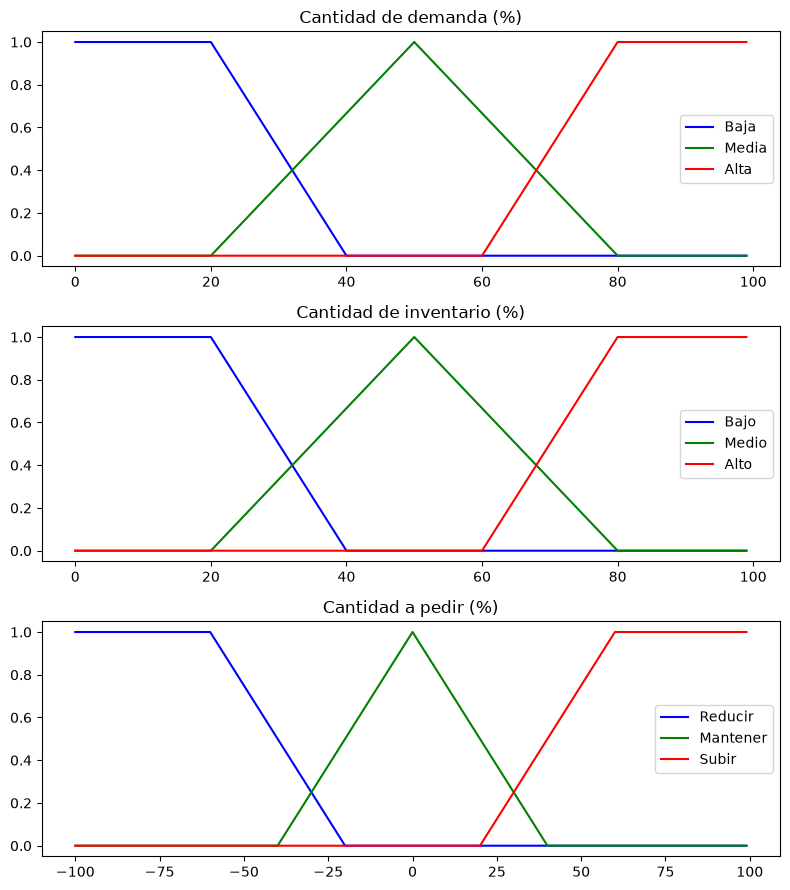

In [4]:
fig, (ax0, ax1, ax2) = plt.subplots(nrows=3, figsize=(8, 9))

ax0.plot(demanda.universe, demanda['baja'].mf, 'b', linewidth=1.5, label='Baja')
ax0.plot(demanda.universe, demanda['media'].mf, 'g', linewidth=1.5, label='Media')
ax0.plot(demanda.universe, demanda['alta'].mf, 'r', linewidth=1.5, label='Alta')
ax0.set_title('Cantidad de demanda (%)')
ax0.legend()

ax1.plot(inventario.universe, inventario['bajo'].mf, 'b', linewidth=1.5, label='Bajo')
ax1.plot(inventario.universe, inventario['medio'].mf, 'g', linewidth=1.5, label='Medio')
ax1.plot(inventario.universe, inventario['alto'].mf, 'r', linewidth=1.5, label='Alto')
ax1.set_title('Cantidad de inventario (%)')
ax1.legend()

ax2.plot(pedido.universe, pedido['reducir'].mf, 'b', linewidth=1.5, label='Reducir')
ax2.plot(pedido.universe, pedido['mantener'].mf, 'g', linewidth=1.5, label='Mantener')
ax2.plot(pedido.universe, pedido['subir'].mf, 'r', linewidth=1.5, label='Subir')
ax2.set_title('Cantidad a pedir (%)')
ax2.legend()

plt.tight_layout()
plt.show()

#### 4. Definición de reglas

In [5]:
reglas:list[ctrl.Rule] = []
# Si la demanda es alta y el inventario es moderado, entonces aumentar el pedido.
reglas.append(ctrl.Rule(demanda["alta"] & inventario["medio"], pedido["subir"]))
# Si la demanda es baja y el inventario es alto, entonces reducir el pedido.
reglas.append(ctrl.Rule(demanda["baja"] & inventario["alto"], pedido["reducir"]))
# Si la demanda es moderada y el inventario es moderado, entonces mantener el mismo nivel de pedido.
reglas.append(ctrl.Rule(demanda["media"] & inventario["medio"], pedido["mantener"]))
# Si la demanda es incierta y el inventario es bajo, entonces aumentar el pedido para prevenir una posible escasez.
reglas.append(ctrl.Rule(inventario["bajo"], pedido["subir"]))
# Si la demanda es incierta y el inventario es alto, entonces reducir el pedido para prevenir un exceso de inventario.
reglas.append(ctrl.Rule(inventario["alto"], pedido["reducir"]))

### 5. Sistema y simulación

Simulación de pedido: subir -40.05%


/Users/erik/Desktop/Cosicas/Progr/PIA_SBRFUZZY/.venv/lib/python3.14/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


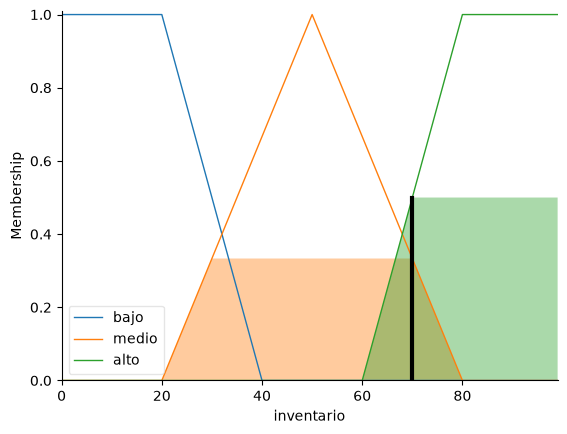

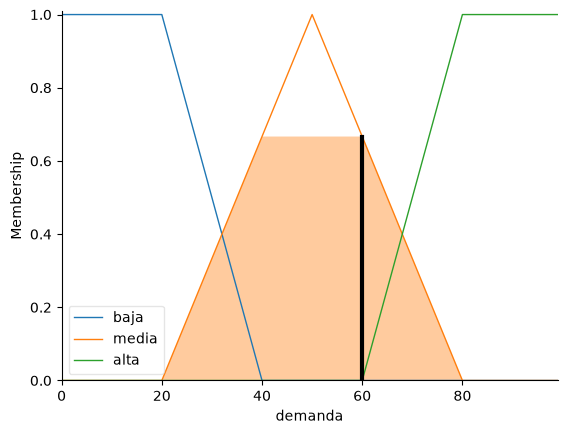

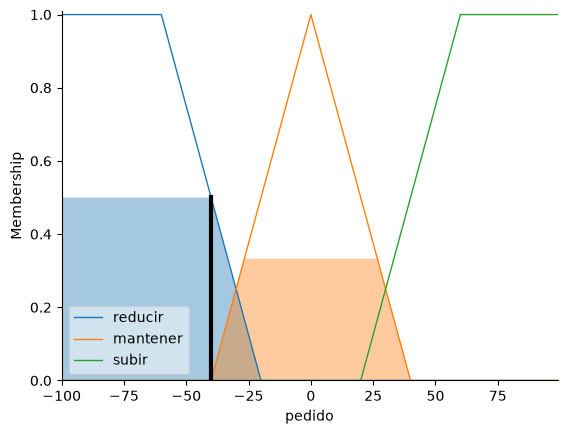

In [6]:
sistema = ctrl.ControlSystem(reglas)
sim = ctrl.ControlSystemSimulation(sistema)
sim.input['inventario'] = 70
sim.input['demanda'] = 60
sim.compute()
print(f"Simulación de pedido: {"subir"} {sim.output['pedido']:.2f}%")
inventario.view(sim)
demanda.view(sim)
pedido.view(sim)